**Standalone analysis notebook** — reads from exported CSVs in `data/processed/`, no database required.

This notebook analyzes the Fort Lauderdale / Broward County short-term rental market using data from [Inside Airbnb](https://insideairbnb.com/). The dataset covers **4 quarterly snapshots** (June 2024 – March 2025) with ~17,000 active listings per snapshot.

**Metrics calculated from calendar availability data:**

- **ADR** (Average Daily Rate) — mean nightly price on booked days
- **Occupancy** — booked days / available days, capped at 70%
- **RevPAR** (Revenue Per Available Room) — ADR × occupancy rate
- **Expected Revenue** — projected annual gross revenue per listing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore")

# Dark theme for GitHub-friendly visuals
plt.rcParams.update({
    "legend.labelcolor": "#c9d1d9", "legend.facecolor": "#161b22",
    "legend.edgecolor": "#30363d", "legend.framealpha": 0.9,
    "figure.facecolor": "#0d1117", "axes.facecolor": "#161b22",
    "axes.edgecolor": "#30363d", "axes.labelcolor": "#c9d1d9",
    "text.color": "#c9d1d9", "xtick.color": "#8b949e",
    "ytick.color": "#8b949e", "grid.color": "#21262d",
    "grid.alpha": 0.6, "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold",
})
PALETTE = ["#58a6ff", "#3fb950", "#d29922", "#f85149", "#bc8cff", "#79c0ff"]

# Load data
cal = pd.read_csv("../data/processed/calendar_metrics.csv", parse_dates=["snapshot_date"])
adv = pd.read_csv("../data/processed/listings_adv_metrics.csv")

print(f"Calendar metrics: {cal.shape[0]:,} rows across {cal.snapshot_date.nunique()} snapshots")
print(f"Listing profiles: {adv.shape[0]:,} listings")
print(f"Snapshot range: {cal.snapshot_date.min():%B %Y} — {cal.snapshot_date.max():%B %Y}")

Calendar metrics: 68,036 rows across 4 snapshots
Listing profiles: 68,038 listings
Snapshot range: June 2024 — March 2025


***

## 1. Market Overview

How many listings are active, and what types of properties dominate?

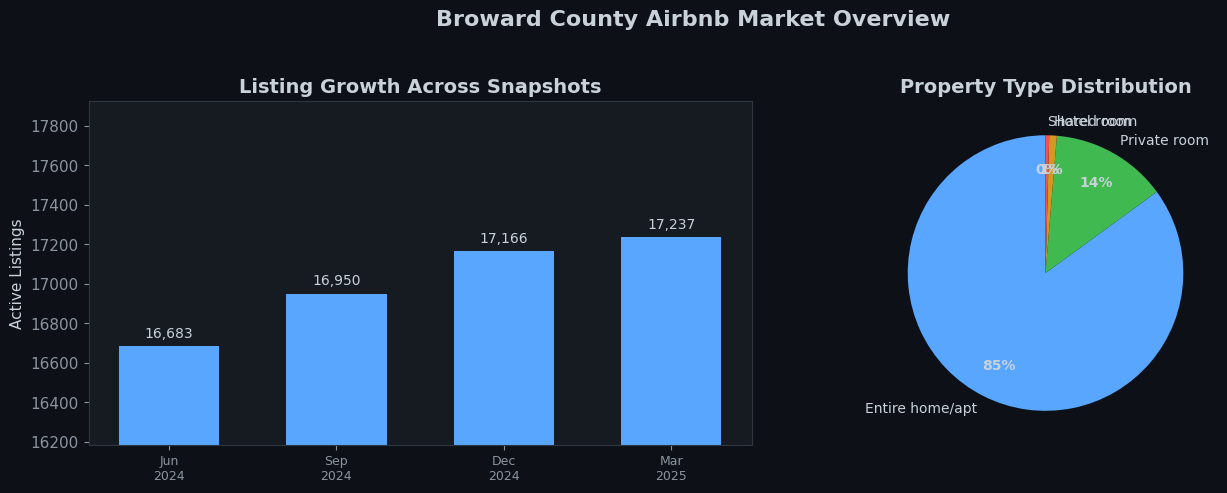


Market grew 3.3% over the observation period (16,683 → 17,237 listings)
Entire homes dominate at 85% of inventory


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Listing count by snapshot
counts = cal.groupby("snapshot_date")["listing_id"].nunique()
bars = axes[0].bar(range(len(counts)), counts.values, color=PALETTE[0], width=0.6)
axes[0].set_xticks(range(len(counts)))
axes[0].set_xticklabels(counts.index.strftime("%b\n%Y"), fontsize=9)
axes[0].set_ylabel("Active Listings")
axes[0].set_title("Listing Growth Across Snapshots")
axes[0].set_ylim(counts.min() * 0.97, counts.max() * 1.04)
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 30,
                 f"{v:,}", ha="center", va="bottom", fontsize=10, color="#c9d1d9")

# Room type breakdown
rt = adv["room_type"].value_counts()
wedges, texts, autotexts = axes[1].pie(
    rt.values, labels=rt.index, autopct="%1.0f%%",
    colors=PALETTE[:len(rt)], textprops={"color": "#c9d1d9", "fontsize": 10},
    pctdistance=0.75, startangle=90)
for at in autotexts:
    at.set_fontweight("bold")
axes[1].set_title("Property Type Distribution")

fig.suptitle("Broward County Airbnb Market Overview", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

growth = (counts.iloc[-1] - counts.iloc[0]) / counts.iloc[0]
print(f"\nMarket grew {growth:.1%} over the observation period ({counts.iloc[0]:,} → {counts.iloc[-1]:,} listings)")
print(f"Entire homes dominate at {rt.iloc[0]/rt.sum():.0%} of inventory")

***

## 2. Pricing Analysis

What do nightly rates look like across the market?

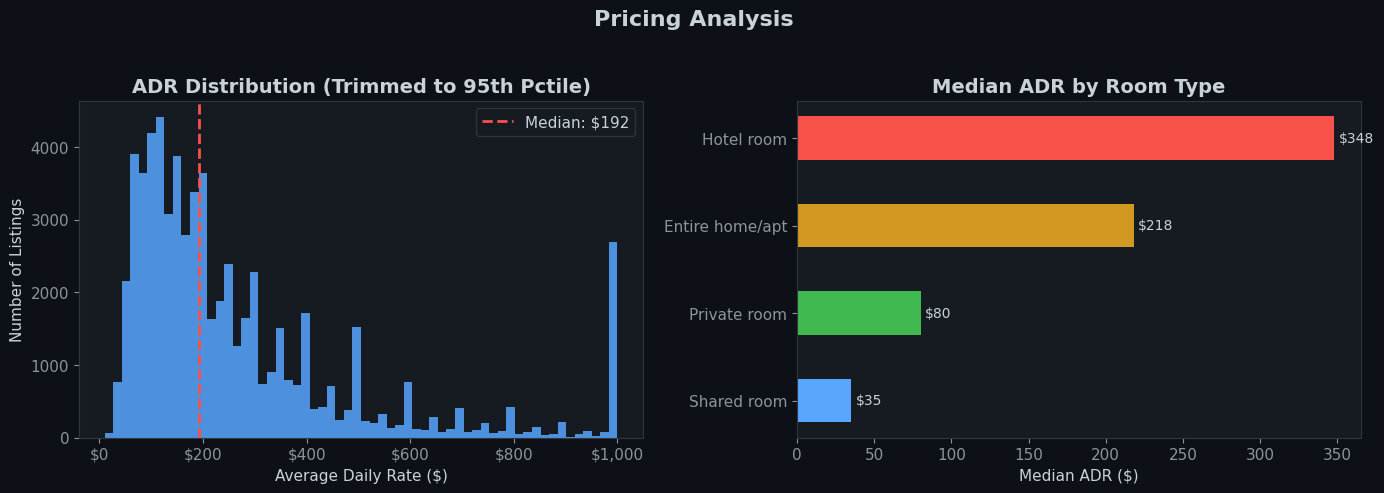

Median ADR: $192 | Mean ADR: $268
Right-skewed distribution — luxury properties pull the mean above the median


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ADR distribution
adr = adv["adr_avg"].dropna()
adr_trim = adr[(adr > 0) & (adr <= adr.quantile(0.95))]
axes[0].hist(adr_trim, bins=60, color=PALETTE[0], edgecolor="none", alpha=0.85)
axes[0].axvline(adr_trim.median(), color=PALETTE[3], ls="--", lw=2,
                label=f"Median: ${adr_trim.median():,.0f}")
axes[0].set_xlabel("Average Daily Rate ($)")
axes[0].set_ylabel("Number of Listings")
axes[0].set_title("ADR Distribution (Trimmed to 95th Pctile)")
axes[0].legend(facecolor="#161b22", edgecolor="#30363d")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

# Median ADR by room type
med_adr = adv.groupby("room_type")["adr_avg"].median().sort_values(ascending=True)
bars = axes[1].barh(range(len(med_adr)), med_adr.values,
                     color=[PALETTE[i] for i in range(len(med_adr))], height=0.5)
axes[1].set_yticks(range(len(med_adr)))
axes[1].set_yticklabels(med_adr.index)
axes[1].set_xlabel("Median ADR ($)")
axes[1].set_title("Median ADR by Room Type")
for bar, v in zip(bars, med_adr.values):
    axes[1].text(v + 3, bar.get_y() + bar.get_height()/2,
                 f"${v:,.0f}", va="center", fontsize=10, color="#c9d1d9")

fig.suptitle("Pricing Analysis", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

print(f"Median ADR: ${adr_trim.median():,.0f} | Mean ADR: ${adr_trim.mean():,.0f}")
print(f"Right-skewed distribution — luxury properties pull the mean above the median")

***

## 3. Occupancy Patterns

How utilized is the Broward County rental market?

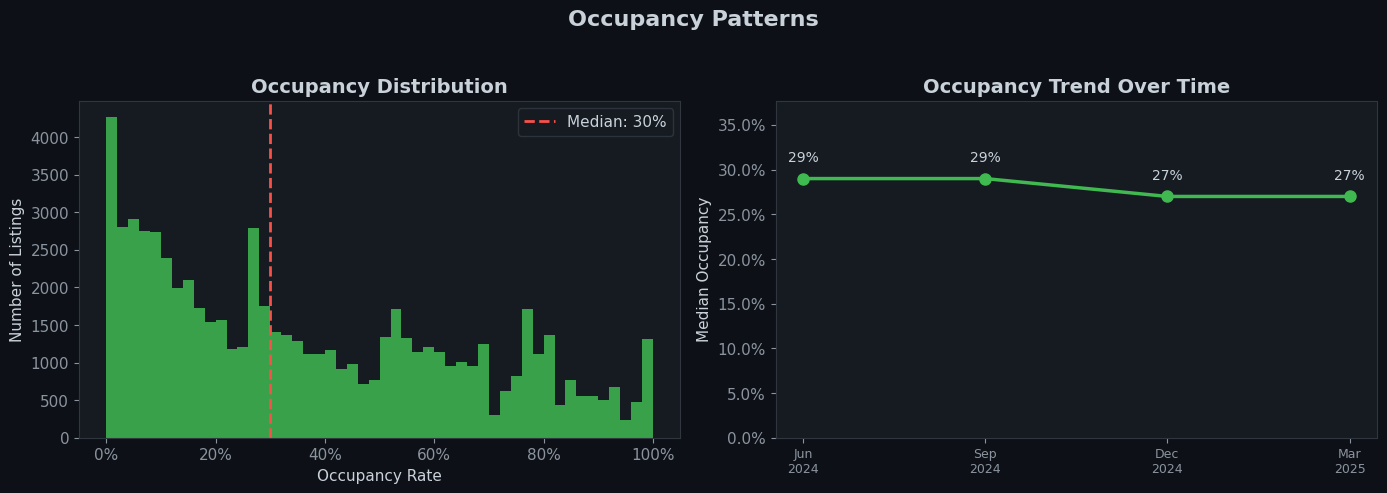

23% of listings have <10% occupancy (likely inactive or seasonal)
24% of listings exceed 60% occupancy (high performers)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Occupancy distribution
occ = adv["occupancy_avg"].dropna()
axes[0].hist(occ, bins=50, color=PALETTE[1], edgecolor="none", alpha=0.85)
axes[0].axvline(occ.median(), color=PALETTE[3], ls="--", lw=2,
                label=f"Median: {occ.median():.0%}")
axes[0].set_xlabel("Occupancy Rate")
axes[0].set_ylabel("Number of Listings")
axes[0].set_title("Occupancy Distribution")
axes[0].legend(facecolor="#161b22", edgecolor="#30363d")
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

# Occupancy trend
med_occ_snap = cal.groupby("snapshot_date")["occupancy"].median()
axes[1].plot(range(len(med_occ_snap)), med_occ_snap.values,
             marker="o", color=PALETTE[1], linewidth=2.5, markersize=8)
axes[1].set_xticks(range(len(med_occ_snap)))
axes[1].set_xticklabels(med_occ_snap.index.strftime("%b\n%Y"), fontsize=9)
axes[1].set_ylabel("Median Occupancy")
axes[1].set_title("Occupancy Trend Over Time")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_ylim(0, med_occ_snap.max() * 1.3)
for i, v in enumerate(med_occ_snap.values):
    axes[1].annotate(f"{v:.0%}", (i, v), textcoords="offset points",
                     xytext=(0, 12), ha="center", fontsize=10, color="#c9d1d9")

fig.suptitle("Occupancy Patterns", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

low_occ = (occ < 0.10).mean()
high_occ = (occ > 0.60).mean()
print(f"{low_occ:.0%} of listings have <10% occupancy (likely inactive or seasonal)")
print(f"{high_occ:.0%} of listings exceed 60% occupancy (high performers)")

***

## 4. Revenue Performance

Which areas generate the most revenue per available night?

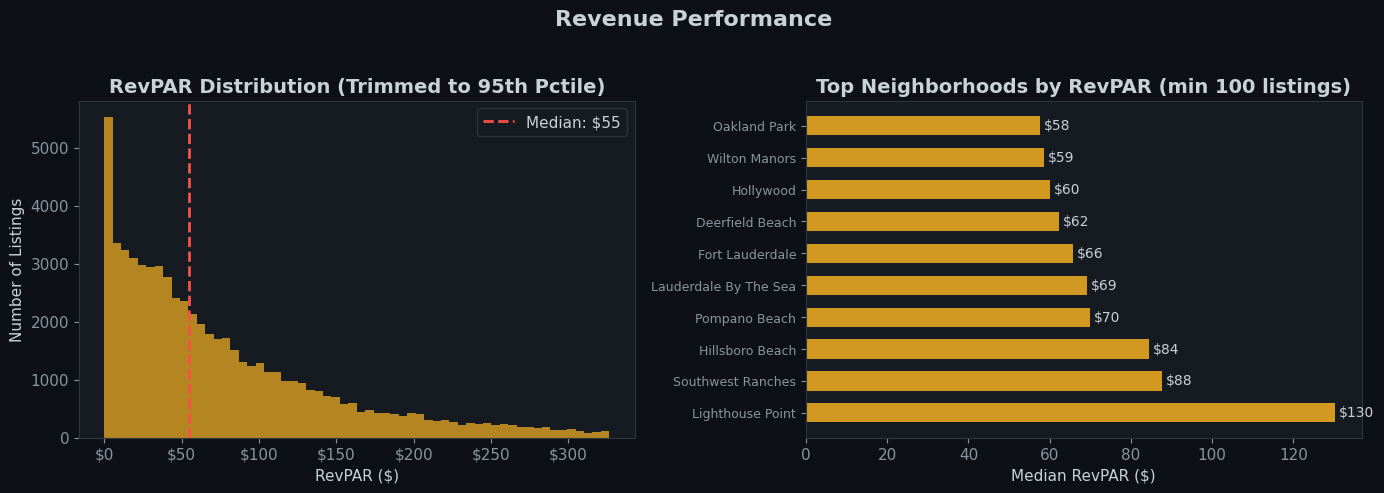

Lighthouse Point leads with $130/night RevPAR
Median market RevPAR: $55/night


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RevPAR distribution
revpar = adv["revpar_avg"].dropna()
revpar_trim = revpar[(revpar > 0) & (revpar <= revpar.quantile(0.95))]
axes[0].hist(revpar_trim, bins=60, color=PALETTE[2], edgecolor="none", alpha=0.85)
axes[0].axvline(revpar_trim.median(), color=PALETTE[3], ls="--", lw=2,
                label=f"Median: ${revpar_trim.median():,.0f}")
axes[0].set_xlabel("RevPAR ($)")
axes[0].set_ylabel("Number of Listings")
axes[0].set_title("RevPAR Distribution (Trimmed to 95th Pctile)")
axes[0].legend(facecolor="#161b22", edgecolor="#30363d")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

# Top neighborhoods
top_n = adv.groupby("neighbourhood_cleansed")["revpar_avg"].agg(["median", "count"])
top_n = top_n[top_n["count"] >= 100].nlargest(10, "median")
bars = axes[1].barh(range(len(top_n)), top_n["median"].values,
                     color=PALETTE[2], height=0.6)
axes[1].set_yticks(range(len(top_n)))
axes[1].set_yticklabels(top_n.index, fontsize=9)
axes[1].set_xlabel("Median RevPAR ($)")
axes[1].set_title("Top Neighborhoods by RevPAR (min 100 listings)")
for bar, v in zip(bars, top_n["median"].values):
    axes[1].text(v + 1, bar.get_y() + bar.get_height()/2,
                 f"${v:,.0f}", va="center", fontsize=10, color="#c9d1d9")

fig.suptitle("Revenue Performance", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

print(f"Lighthouse Point leads with ${top_n['median'].iloc[0]:,.0f}/night RevPAR")
print(f"Median market RevPAR: ${revpar_trim.median():,.0f}/night")

***

## 5. Host Analysis

How does Superhost status affect performance, and how concentrated is ownership?

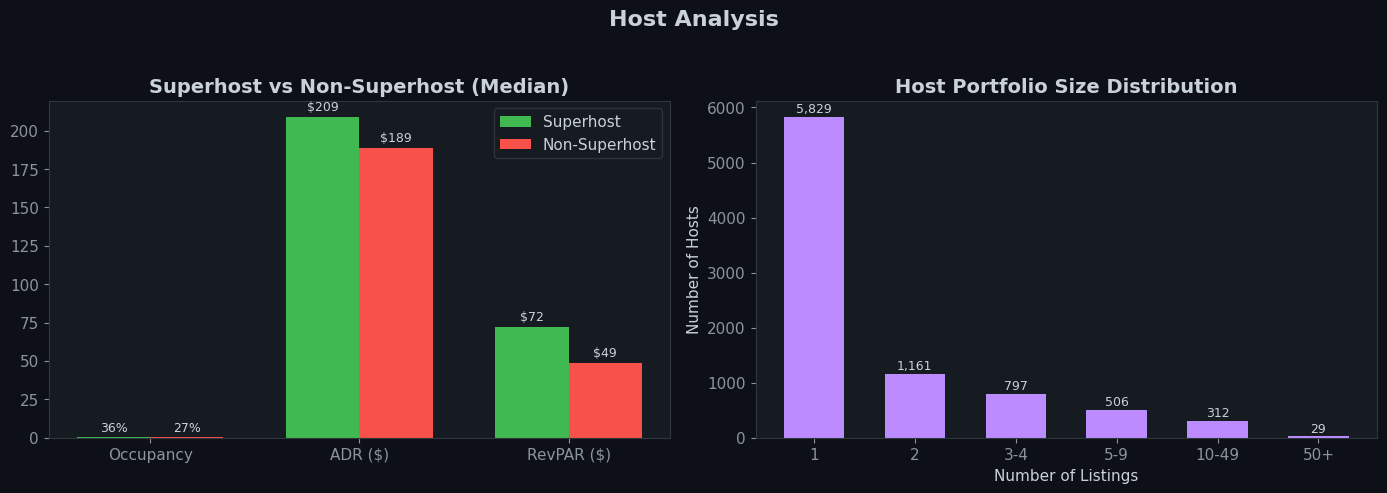

68% of hosts operate a single listing
341 hosts manage 10+ listings (professional operators)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Superhost comparison
sh = adv.groupby("host_is_superhost")[["occupancy_avg", "adr_avg", "revpar_avg"]].median()
sh.index = sh.index.map({"t": "Superhost", "f": "Non-Superhost"})
x = np.arange(3)
w = 0.35
bars1 = axes[0].bar(x - w/2, sh.loc["Superhost"], w, label="Superhost",
                      color=PALETTE[1])
bars2 = axes[0].bar(x + w/2, sh.loc["Non-Superhost"], w, label="Non-Superhost",
                      color=PALETTE[3])
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Occupancy", "ADR ($)", "RevPAR ($)"])
axes[0].set_title("Superhost vs Non-Superhost (Median)")
axes[0].legend(facecolor="#161b22", edgecolor="#30363d")
for bars in [bars1, bars2]:
    for bar in bars:
        val = bar.get_height()
        label = f"{val:.0%}" if val < 1 else f"${val:,.0f}"
        axes[0].text(bar.get_x() + bar.get_width()/2, val + 2,
                     label, ha="center", va="bottom", fontsize=9, color="#c9d1d9")

# Host portfolio size
host_counts = adv.groupby("host_id")["listing_id"].nunique()
bins = [1, 2, 3, 5, 10, 50, host_counts.max() + 1]
labels = ["1", "2", "3-4", "5-9", "10-49", "50+"]
host_cats = pd.cut(host_counts, bins=bins, labels=labels, right=False)
cat_counts = host_cats.value_counts().reindex(labels)
bars = axes[1].bar(range(len(cat_counts)), cat_counts.values,
                    color=PALETTE[4], width=0.6)
axes[1].set_xticks(range(len(cat_counts)))
axes[1].set_xticklabels(labels)
axes[1].set_xlabel("Number of Listings")
axes[1].set_ylabel("Number of Hosts")
axes[1].set_title("Host Portfolio Size Distribution")
for bar, v in zip(bars, cat_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 20,
                 f"{v:,}", ha="center", va="bottom", fontsize=9, color="#c9d1d9")

fig.suptitle("Host Analysis", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

single = (host_counts == 1).mean()
multi = (host_counts >= 10).sum()
print(f"{single:.0%} of hosts operate a single listing")
print(f"{multi:,} hosts manage 10+ listings (professional operators)")

***

## 6. Neighborhood Comparison

Side-by-side view of the top 8 neighborhoods across multiple dimensions.

In [7]:
top_hoods = adv["neighbourhood_cleansed"].value_counts().head(8).index
hood_data = adv[adv["neighbourhood_cleansed"].isin(top_hoods)]

summary = hood_data.groupby("neighbourhood_cleansed").agg(
    listings=("listing_id", "nunique"),
    median_adr=("adr_avg", "median"),
    median_occ=("occupancy_avg", "median"),
    median_revpar=("revpar_avg", "median"),
    median_revenue=("expected_revenue_avg", "median"),
    pct_superhost=("host_is_superhost", lambda x: (x == "t").mean()),
).sort_values("median_revpar", ascending=False)

summary["median_occ"] = summary["median_occ"].map("{:.0%}".format)
summary["pct_superhost"] = summary["pct_superhost"].map("{:.0%}".format)
summary["median_adr"] = summary["median_adr"].map("${:,.0f}".format)
summary["median_revpar"] = summary["median_revpar"].map("${:,.0f}".format)
summary["median_revenue"] = summary["median_revenue"].map("${:,.0f}".format)
summary.columns = ["Listings", "Median ADR", "Median Occ", "Median RevPAR",
                    "Median Revenue", "% Superhost"]

print("Top 8 Neighborhoods — Ranked by RevPAR")
print("=" * 90)
summary

Top 8 Neighborhoods — Ranked by RevPAR


,Listings,Median ADR,Median Occ,Median RevPAR,Median Revenue,% Superhost
neighbourhood_cleansed,,,,,,
Pompano Beach,2368,$188,35%,$70,"$25,492",45%
Fort Lauderdale,5818,$220,31%,$66,"$23,975",48%
Deerfield Beach,920,$199,32%,$62,"$22,769",51%
Hollywood,5721,$204,27%,$60,"$21,890",28%
Wilton Manors,586,$208,30%,$59,"$21,369",62%
Oakland Park,659,$199,33%,$58,"$21,052",55%
Dania Beach,878,$145,34%,$51,"$18,589",35%
Hallandale Beach,2365,$229,19%,$47,"$16,980",19%


***

## Key Findings

1. **Steady market growth** — Broward County added ~550 net new listings over 9 months (+3.3%), suggesting continued STR investment despite regulatory uncertainty.

2. **Pricing is heavily right-skewed** — Median ADR of ~\$192 vs. mean of ~\$370 indicates a long tail of luxury properties pulling averages up. Median is the better benchmark for market entry analysis.

3. **Low median occupancy signals oversupply** — At ~30% median occupancy, the majority of listings sit empty most of the year. Only ~20% of listings exceed 60% occupancy.

4. **Superhost status correlates with higher occupancy** — Superhosts achieve meaningfully higher occupancy and RevPAR, though the ADR gap is smaller. The value of the badge appears to be in booking volume, not pricing power.

5. **Coastal neighborhoods command premiums** — Lighthouse Point and Southwest Ranches lead in RevPAR, while the largest markets (Fort Lauderdale, Hollywood) show moderate per-listing performance due to saturation.

***

*Data: [Inside Airbnb](https://insideairbnb.com/) | Broward County, FL | June 2024 — March 2025*